# Deep Learning Model Building From Scratch Uing Tensorflow/Keras

In [17]:
import numpy as np
import tensorflow as tf
from keras.datasets import mnist

In [18]:
# Load data
(x_train,y_train),(x_test,y_test)=mnist.load_data()

In [19]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


<function matplotlib.pyplot.show(close=None, block=None)>

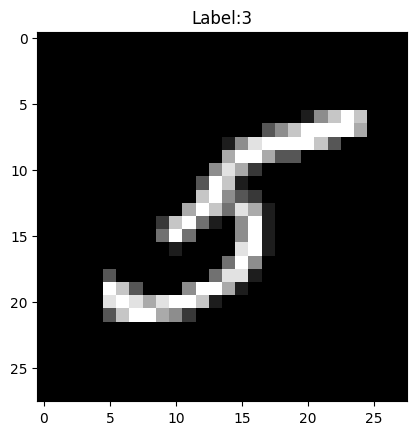

In [20]:
import matplotlib.pylab as plt
plt.imshow(x_train[35],cmap="gray")
plt.title(f"Label:{y_train[30]}")
plt.show

In [21]:
print(type(y_train))

<class 'numpy.ndarray'>


In [22]:
print(y_train)

[5 0 4 ... 5 6 8]


In [23]:
import pandas as pd
y_train_1=pd.DataFrame(y_train)
y_train_1.value_counts()

0
1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64

In [24]:
type(x_train)

numpy.ndarray

In [25]:
type(x_train[0])

numpy.ndarray

In [26]:
# Normalize the data
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")
x_train = x_train / 255.0
x_test = x_test / 255.0
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [27]:
print(x_train.shape)
print(x_test.shape)
print(x_train.size)

(60000, 28, 28)
(10000, 28, 28)
47040000


In [28]:
# Reshape x_train and x_test
x_train = x_train.reshape(60000, 28 * 28)
x_test = x_test.reshape(10000, 28 * 28)

print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


In [29]:
# let us build sequential Model
from keras.models import Sequential
from keras.layers import Dense

In [33]:
# Define Sequential Model
model=Sequential()

# let us add input layer
model.add(Dense(units=784,activation="relu",input_dim=28*28))

# let us add Hidden Layer
model.add(Dense(units=10,activation="relu"))

# let us add second hidden layer
model.add(Dense(units=10,activation="relu"))

#let us add ouput layer
model.add(Dense(units=10,activation="softmax"))

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,510 (2.38 MB)

 Trainable params: 623,510 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Let us compile the model
model.compile(optimizer="ADAM",
             loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])

In [32]:
# Let us fit the model
history=model.fit(x_train,y_train,epochs=15,validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8815 - loss: 0.3989 - val_accuracy: 0.9482 - val_loss: 0.2005
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9619 - loss: 0.1387 - val_accuracy: 0.9628 - val_loss: 0.1336
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9730 - loss: 0.0940 - val_accuracy: 0.9685 - val_loss: 0.1098
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9808 - loss: 0.0658 - val_accuracy: 0.9717 - val_loss: 0.1115
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9852 - loss: 0.0492 - val_accuracy: 0.9711 - val_loss: 0.1115
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9887 - loss: 0.0367 - val_accuracy: 0.9713 - val_loss: 0.1181
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9901 - loss: 0.0300 - val_accuracy: 0.9741 - val_loss: 0.1155
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9916 - loss: 0.0265 - 

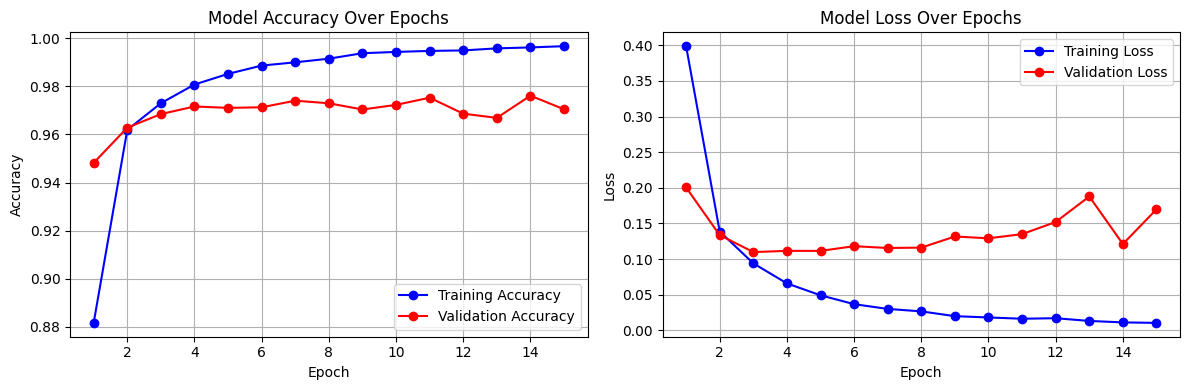

In [36]:
import matplotlib.pyplot as plt

# Extract metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

# Create two plots
plt.figure(figsize=(12, 4))
# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()